# 05 — Entraînement baseline vision (KneeNet)

Lance `src/train/train.py` avec `configs/baseline.yaml` et affiche les courbes.

- Entrée : 3 plans (sag/cor/ax, fluid prioritaire) × 24 slices × 224², normalisés GPU
- Modèle : ConvNeXt-tiny partagé (24 canaux = slices) → GAP → concat 3×768 → MLP → 12 logits
- Loss : BCE masquée (-1 = ignoré). Train (avec aug) vs val (sans aug) dans `history.json`
- Métrique : macro-AUC val (pseudo-labels) vs macro-AUC gold (58, jamais pour le checkpoint)

Sur RTX 3070 (8 Go) : batch 16 ≈ 4 Go VRAM, ~3–4 min/epoch.

Les colonnes `val_loss` et `gold_macro_auc` n'existent qu'après une run **post** ce changement. Relancer l'entraînement pour les graphes complets.

In [4]:
# L'entrainement se lance en terminal (plus robuste que dans le notebook) :
#   python -X utf8 -m src.train.train --config configs/baseline.yaml
# Cette cellule attend la fin et affiche l'historique.
import json, time
from pathlib import Path

run_dir = Path.cwd().parent / 'checkpoints' / 'baseline_v6_blend'
hist_path = run_dir / 'history.json'
print('en attente de', hist_path, '...')
while not hist_path.exists():
    time.sleep(30)
print('termine')

en attente de c:\Users\sulta\Documents\RSNA-comp\checkpoints\baseline_v5_nopw\history.json ...
termine


,epoch,loss,val_loss,val_macro_auc,gold_macro_auc
0,1,0.6310,0.6187,0.5661,0.5185
1,2,0.6092,0.6139,0.6816,0.5532
2,3,0.5751,0.5383,0.7471,0.6301
3,4,0.5524,0.5528,0.7515,0.6298
4,5,0.5339,0.5063,0.7761,0.6289
5,6,0.5056,0.4833,0.8032,0.6524
6,7,0.4834,0.4606,0.8268,0.6690
7,8,0.4419,0.4554,0.8319,0.6590
8,9,0.4084,0.4482,0.8346,0.6652
9,10,0.3811,0.4405,0.8407,0.6622


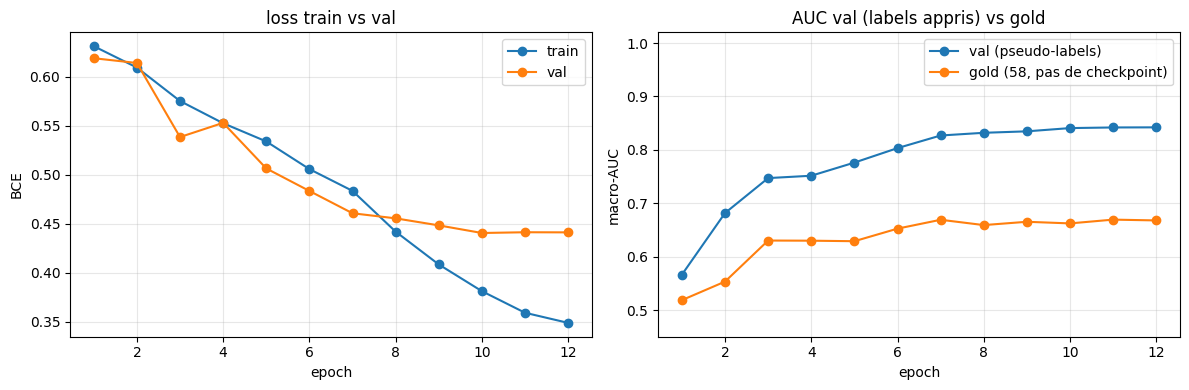

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(json.loads(hist_path.read_text()))
show = [c for c in ('epoch', 'loss', 'val_loss', 'val_macro_auc', 'gold_macro_auc') if c in hist.columns]
display(hist[show].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist.epoch, hist.loss, marker='o', label='train')
if 'val_loss' in hist.columns:
    axes[0].plot(hist.epoch, hist.val_loss, marker='o', label='val')
else:
    print('val_loss absent : relancer train.py pour la comparer a la train loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('BCE')
axes[0].set_title('loss train vs val')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist.epoch, hist.val_macro_auc, marker='o', label='val (pseudo-labels)')
if 'gold_macro_auc' in hist.columns:
    axes[1].plot(hist.epoch, hist.gold_macro_auc, marker='o', label='gold (58, pas de checkpoint)')
else:
    print('gold_macro_auc absent : relancer train.py pour la courbe gold vs val')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('macro-AUC')
axes[1].set_title('AUC val (labels appris) vs gold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0.45, 1.02)

plt.tight_layout()
plt.show()

In [6]:
# Sanity check gold du best.pt (58 etudes, jamais pour le checkpoint)
gold_path = run_dir / 'gold_sanity.json'
if gold_path.exists():
    gold = json.loads(gold_path.read_text())
    ep = gold.get('epoch', '?')
    print(f"macro-AUC gold (best.pt, epoch {ep}) :", round(gold['macro_auc'], 4))
    display(pd.Series(gold['per_target']).sort_values(ascending=False).round(3))
    if 'gold_macro_auc' in hist.columns:
        last = hist.iloc[-1]
        print('derniere epoch — val AUC :', round(last.val_macro_auc, 4),
              '| gold AUC :', round(last.gold_macro_auc, 4),
              '| ecart :', round(last.val_macro_auc - last.gold_macro_auc, 4))
else:
    print('pas de gold_sanity.json')

macro-AUC gold (best.pt, epoch 12) : 0.6678


Baker's             0.868
Effusion            0.854
PF OA               0.749
Medial OA           0.745
Synovitis           0.742
Lateral Meniscus    0.723
Medial Meniscus     0.605
Lateral OA          0.596
ACL                 0.591
Contusion           0.544
Fracture            0.526
MCL                 0.471
dtype: float64

derniere epoch — val AUC : 0.8421 | gold AUC : 0.6678 | ecart : 0.1743
